In [19]:
%pip install numpy matplotlib astropy astroquery firefly-client

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import http.client
import time
import urllib.error

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time
from astroquery.ipac.irsa import Irsa

from astroquery.ipac.irsa import Irsa

from firefly_client import FireflyClient

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

In [23]:
ra_deg = 304.693508808
dec_deg = 42.4436872991

coord = SkyCoord(ra_deg, dec_deg, unit='deg')
search_radius = 1 * u.arcsec

results = Irsa.query_sia(
    pos=(coord, search_radius),
    collection=['spherex_dr1', 'spherex_qr3'],
    time=(Time('2025-07-01'), Time('2026-08-01')),   # range
)

len(results)

results.colnames

['s_ra',
 's_dec',
 'facility_name',
 'instrument_name',
 'dataproduct_subtype',
 'calib_level',
 'dataproduct_type',
 'energy_bandpassname',
 'energy_emband',
 'obs_id',
 's_resolution',
 'em_min',
 'em_max',
 'em_res_power',
 'proposal_title',
 'access_url',
 'access_format',
 'access_estsize',
 't_exptime',
 's_region',
 'obs_collection',
 'obs_intent',
 'algorithm_name',
 'facility_keywords',
 'instrument_keywords',
 'environment_photometric',
 'proposal_id',
 'proposal_pi',
 'proposal_project',
 'target_name',
 'target_type',
 'target_standard',
 'target_moving',
 'target_keywords',
 'obs_release_date',
 's_xel1',
 's_xel2',
 's_pixel_scale',
 'position_timedependent',
 't_min',
 't_max',
 't_resolution',
 't_xel',
 'obs_publisher_did',
 's_fov',
 'em_xel',
 'pol_states',
 'pol_xel',
 'cloud_access',
 'o_ucd',
 'upload_row_id']

https://irsa.ipac.caltech.edu/ibe/data/spherex/qr3/level2/2026W20_2A/l2b-v27-2026-267/3/level2_2026W20_2A_0058_4D3_spx_l2b-v27-2026-267.fits
Filename: C:\Users\prasa\.cache\astropy\download\url\f42f8feb8ab54e9f020a6a1fece1c899\contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       275   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     55   451R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 14J, 252E]   


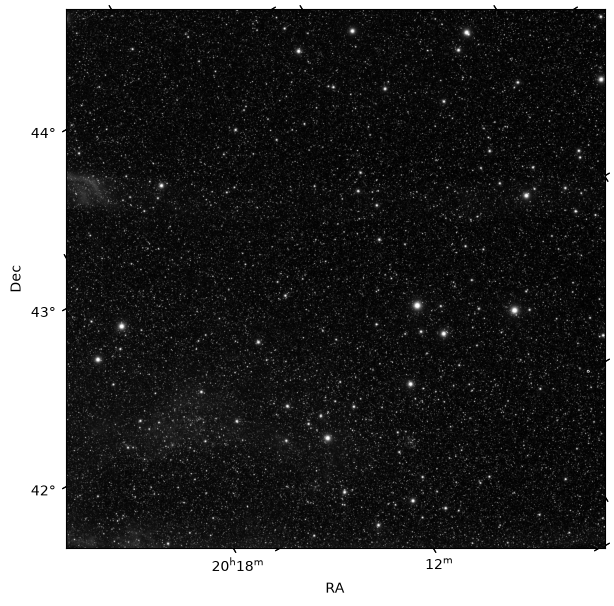

In [ ]:
from astropy.visualization import simple_norm
for result in results:
    spectral_image_url = results['access_url'][0]
    print(spectral_image_url)
    with fits.open(spectral_image_url) as hdul:
        hdul.info()                      # list extensions
        img = hdul["IMAGE"].data
        wcs = WCS(hdul["IMAGE"].header)

    # 3. Plot
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(projection=wcs)
    ax.imshow(img, origin="lower", cmap="gray",
            norm=simple_norm(img, "asinh", percent=99))
    ax.set_xlabel("RA"); ax.set_ylabel("Dec")
plt.show()

In [ ]:
# Max number of times to retry HTTP errors.
max_retries = 3
for attempt in range(max_retries):
    try:
        # Load the data, reading every extension into memory so that
        # hdulist stays usable after the file is closed.
        with fits.open(spectral_image_url, memmap=False) as hdulist:
            for hdu in hdulist:
                hdu.data
        break
    except (TimeoutError, urllib.error.HTTPError, http.client.IncompleteRead):
        if attempt == max_retries - 1:
            raise
        time.sleep(10 * (attempt + 1))

In [25]:
hdulist.info()

Filename: C:\Users\prasa\.cache\astropy\download\url\2edb0eda84f44a114b0a0118c29fe067\contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       293   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   ['J', 'J', 'E', 'E', 'E', 'E', 'J', 'E', 'E', 'E', '1089D']   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   ['9J', '9J', '162E']   


In [26]:
fc = FireflyClient.make_client(url="https://irsa.ipac.caltech.edu/irsaviewer")

fc.reinit_viewer()

{'success': True}

In [27]:
fc.show_fits_image(file_input=spectral_image_url,
             plot_id="spectral_image",
             Title="Spectral Image"
             )

{'success': True}

In [28]:
spectral_image_header = hdulist[1].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT', 'DETECTOR', 'OBSID', 'DATE', 'PSF_FWHM']

for keyword in keywords_to_print:
    value = spectral_image_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

spectral_image_header['WCSNAME*']



EXTNAME: IMAGE
NAXIS1: 2040
NAXIS2: 2040
BUNIT: MJy / sr
DETECTOR: 1
OBSID: 2025W18_1B_0074_2
DATE: 2026-07-16T03:19:15.597
PSF_FWHM: 7.530770327317724


WCSNAMEA= '0-based active pixel coordinates' / Coordinate system title          
WCSNAMEW= 'Approximated per-pixel wavelength and bandwidth' / WCS label         

In [ ]:
wcs = WCS(spectral_image_header)
ra, dec = wcs.wcs.crval
x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
print(ra, dec, x, y)
spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")



303.877766184 40.5489585415 1019.0880637763953 1020.746373505631
INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS